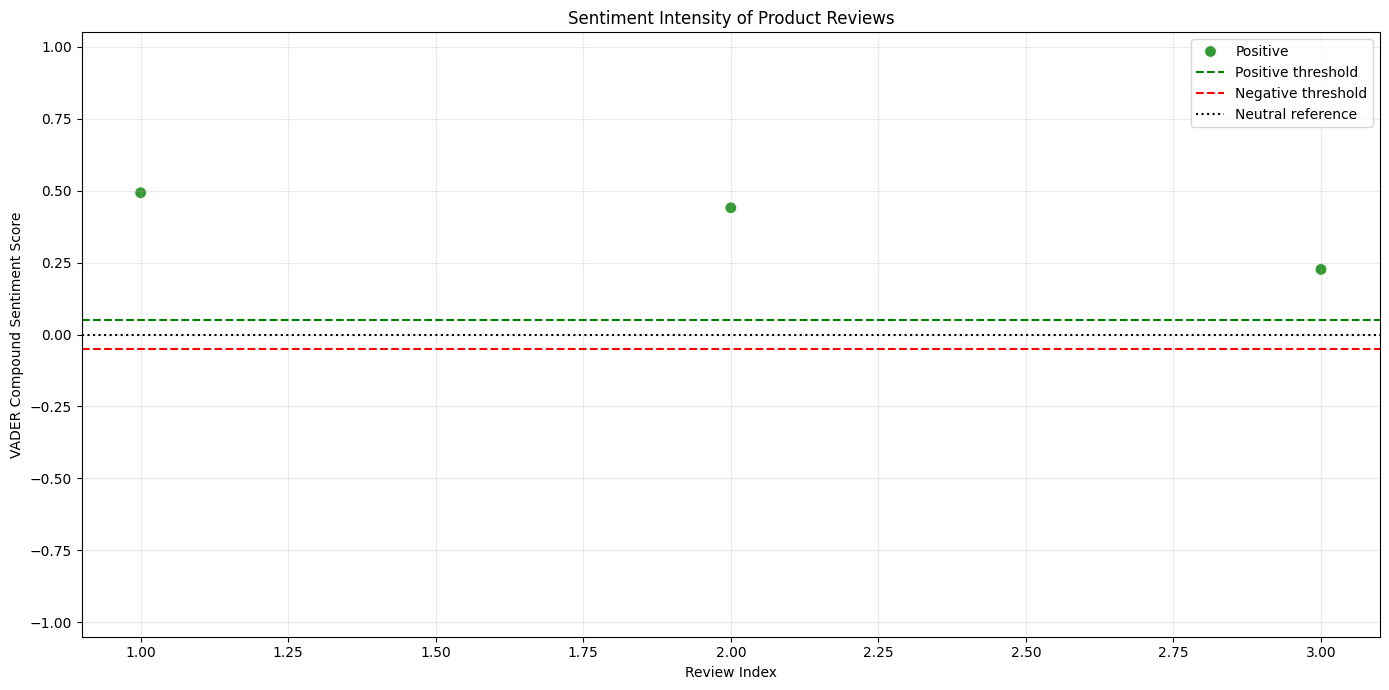

Scatter intensity plot saved successfully.
Saved to: C:\Users\HP\OneDrive\Desktop\reviews.html\sentiment_intensity_scatter.png


In [1]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

folder_path = r"C:\Users\HP\OneDrive\Desktop\reviews.html"
csv_path = os.path.join(folder_path, "sentiment_analysis_results.csv")

df = pd.read_csv(csv_path)

df["vader_compound"] = pd.to_numeric(
    df["vader_compound"], errors="coerce"
)

df = df.dropna(subset=["vader_compound"]).reset_index(drop=True)

df["review_index"] = range(1, len(df) + 1)

palette = {
    "Positive": "green",
    "Negative": "red",
    "Neutral": "gray"
}

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=df,
    x="review_index",
    y="vader_compound",
    hue="vader_sentiment",
    palette=palette,
    s=70,
    alpha=0.8
)

plt.axhline(
    y=0.05, color="green", linestyle="--",
    label="Positive threshold"
)
plt.axhline(
    y=-0.05, color="red", linestyle="--",
    label="Negative threshold"
)
plt.axhline(
    y=0, color="black", linestyle=":",
    label="Neutral reference"
)

plt.ylim(-1.05, 1.05)
plt.xlabel("Review Index")
plt.ylabel("VADER Compound Sentiment Score")
plt.title("Sentiment Intensity of Product Reviews")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()

output_path = os.path.join(
    folder_path, "sentiment_intensity_scatter.png"
)
plt.savefig(output_path, dpi=300)
plt.show()

print("Scatter intensity plot saved successfully.")
print("Saved to:", output_path)